[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/01_hito1_una_corriente.ipynb)

# 01 · Hito 1: una corriente en la MW aislada y en MW + LMC

Con la peticion a modo de enunciado, un progenitor en el apocentro a ~100 kpc, hace 4 Gyr, con la mitad de la velocidad
circular local; su corriente en la MW aislada (modelo A) y en el sistema completo MW + LMC (modelo D).

Como lograr hacerlo? trabajo realizado:
- El sistema MW + LMC se integra hacia atrás 7 Gyr como dos cuerpos con fricción dinámica (tutorial de
  Garavito-Camargo). De ahí salen la posición de la LMC relativa a la MW, $\mathbf x_{\rm LMC}(t)$, y la
  aceleración del centro de la MW, $\mathbf a_{\rm MW}(t)$.
- Todo se escribe en el **marco de la MW** (centro de la MW fijo en el origen). Los cuatro modelos:
  A = MW; B = MW + campo uniforme $-\mathbf a_{\rm MW}(t)$ (masa puntual muy lejana, `TimeInterpolatedPotential`);
  C = MW + LMC móvil; D = MW + LMC móvil + campo uniforme.
- La corriente: `MockStreamGenerator` + `FardalStreamDF`, con las **mismas condiciones iniciales en el pasado y la
  misma semilla** en los cuatro modelos.

In [11]:
# Entorno en Colab clona el repositorio.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.18
  numpy       2.2.6
  scipy       1.16.3
  astropy     7.2.3
  gala        1.12.0
  matplotlib  3.10.0
  pandas      2.2.3
  healpy      1.20.1
  galstreams  1.2.1
Salidas en: /content/drive/MyDrive/lapis26_p3/salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [12]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("01_hito1")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/01_hito1.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: /content/drive/MyDrive/lapis26_p3/salidas/01_hito1_20261028_132443


In [13]:
import time
from p3streams import potenciales as P, corrientes as Co, metricas as Me, figuras as F
t0 = time.time()
sis = P.integrar_sistema()           # MW + LMC hacia atras, con friccion dinamica
mods = P.modelos(sis)                # A, B, C, D
d = sis.d_lmc()
i = np.argmin(d[sis.t > -3000] if (sis.t > -3000).any() else d)
print("Sistema integrado en %.0f s" % (time.time() - t0))
print("LMC hoy a %.1f kpc del centro de la MW; pericentro reciente %.1f kpc hace %.0f Myr"
      % (d[np.argmin(np.abs(sis.t))], d[sis.t > -3000].min(), -sis.t[sis.t > -3000][np.argmin(d[sis.t > -3000])]))

Sistema integrado en 24 s
LMC hoy a 49.7 kpc del centro de la MW; pericentro reciente 47.9 kpc hace 51 Myr


### El progenitor

Polo inicial $\hat{\mathbf n} = -\hat{\mathbf y}$ (órbita polar en el plano $x$–$z$ de la MW), apocentro 100 kpc,
$f = 0.5$, $t_{\rm start} = 4$ Gyr, $10^7\,M_\odot$. Primero se comprueba en la MW aislada que la órbita sea la del
enunciado (pericentro ~27 kpc, excentricidad ~0.6).

In [14]:
N0 = np.array([0.0, -1.0, 0.0])
x0, v0 = Co.condiciones_iniciales(N0, r_apo=100.0, f=0.5, psi_deg=0.0)
orb = Co.orbita(mods["A"], x0, v0, t_inicio=-4000.0)
r = Co.resumen_orbita(orb)
print("x0 = %s kpc, v0 = %s km/s" % (np.round(x0, 2), np.round(v0, 1)))
print("MW aislada: pericentro %.1f kpc, apocentro %.1f kpc, e = %.2f, periodo radial %.2f Gyr"
      % (r["peri_kpc"], r["apo_kpc"], r["ecc"], r["periodo_radial_Myr"] / 1e3))

x0 = [100.   0.   0.] kpc, v0 = [-0.   0.  86.1] km/s
MW aislada: pericentro 26.7 kpc, apocentro 100.0 kpc, e = 0.58, periodo radial 1.65 Gyr


In [15]:
t0 = time.time()
CORR = {m: Co.generar(mods[m], x0, v0, m_prog=1e7, t_inicio=-4000.0) for m in "ABCD"}
print("4 corrientes en %.0f s; %d particulas cada una" % (time.time() - t0, len(CORR["A"]["pos"])))
RES, PERF = {}, {}
for m in "ABCD":
    RES[m], PERF[m] = Me.medir(CORR[m], N0)

4 corrientes en 25 s; 4002 particulas cada una


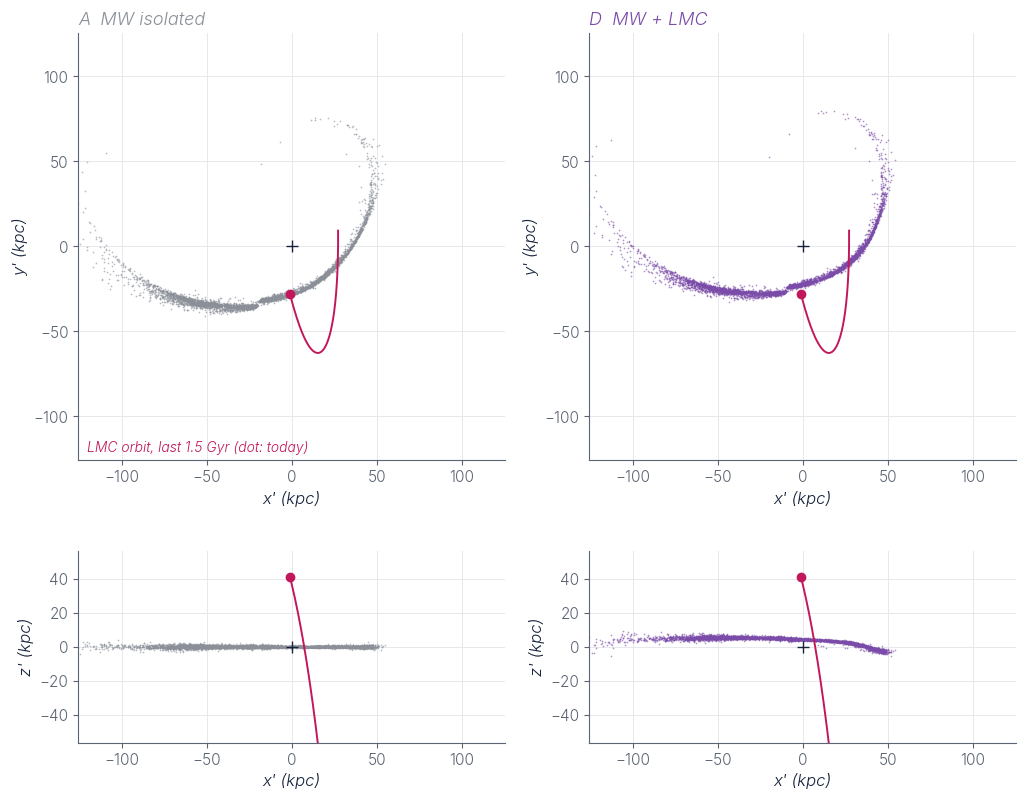

Figura: hito1_corriente_A_D.png 
Milestone 1. Mock stream today (4 Gyr of disruption, 1e7 Msun progenitor starting at apocentre 100 kpc with f = 0.5) in the isolated Milky Way (A) and in the full MW + LMC system (D), in the frame of the initial orbital plane: face-on (top) and edge-on (bottom). Magenta: LMC orbit over the last 1.5 Gyr (dot: today). Cross: MW centre.


In [16]:
fig = F.hito1({m: CORR[m] for m in "AD"}, sis, N0, x0)
PIE = 'Milestone 1. Mock stream today (4 Gyr of disruption, 1e7 Msun progenitor starting at apocentre 100 kpc with f = 0.5) in the isolated Milky Way (A) and in the full MW + LMC system (D), in the frame of the initial orbital plane: face-on (top) and edge-on (bottom). Magenta: LMC orbit over the last 1.5 Gyr (dot: today). Cross: MW centre.'
E.guardar(fig, os.path.join(SAL, 'hito1_corriente_A_D.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito1_corriente_A_D.png', "\n" + PIE)

### Las métricas en A y D

`tilt_polo`: ángulo entre el polo medio de hoy y el polo inicial. `tilt_plano`: ángulo entre el polo inicial y
la normal del plano SVD. `desalineamiento`: mediana de $|\Delta\theta|$ a lo largo de la corriente, vista desde el
Sol con el movimiento propio corregido por el movimiento solar. `dispersion_polos`: mediana del ángulo de
cada polo al polo medio. `grosor`: espesor fuera del plano (1.4826 MAD).

In [17]:
filas = []
for m in "AD":
    for parte in ("todo", "lider", "cola", "vieja", "joven"):
        d = RES[m].get(parte)
        if d:
            filas.append(dict(modelo=m, parte=parte, **{k: round(d[k], 2) for k in Me.METRICAS}))
TAB = pd.DataFrame(filas)
TAB.to_csv(os.path.join(SAL, "hito1_metricas.csv"), index=False)
TAB

,modelo,parte,desalineamiento_deg,dispersion_polos_deg,tilt_polo_deg,tilt_plano_deg,grosor_kpc,tilt_polos_mediana_deg
0,A,todo,0.82,0.75,0.02,0.02,0.50,0.75
1,A,lider,0.95,0.77,0.03,0.05,0.37,0.77
2,A,cola,0.65,0.73,0.02,0.04,0.70,0.73
3,A,vieja,1.06,0.76,0.04,0.04,0.52,0.76
4,A,joven,1.37,0.74,0.00,0.04,0.49,0.74
5,D,todo,3.09,2.80,9.90,8.56,0.62,10.95
6,D,lider,3.59,2.40,8.15,7.73,1.08,7.69
7,D,cola,3.07,1.50,11.75,8.78,0.72,11.89
8,D,vieja,3.58,2.98,8.95,6.17,0.82,9.32
9,D,joven,3.10,1.90,10.88,10.39,0.67,11.50


### La definición literal: coordenadas $(\phi_1, \phi_2)$ de un gran círculo

El paquete mide el desalineamiento en un marco local que sigue la traza (sirve también para corrientes de más de
una vuelta). Aquí está la versión literal del enunciado, con `GreatCircleICRSFrame` ajustado a la corriente
vista desde el Sol: las flechas son la dirección del movimiento propio (corregido por el Sol) en cada tramo.

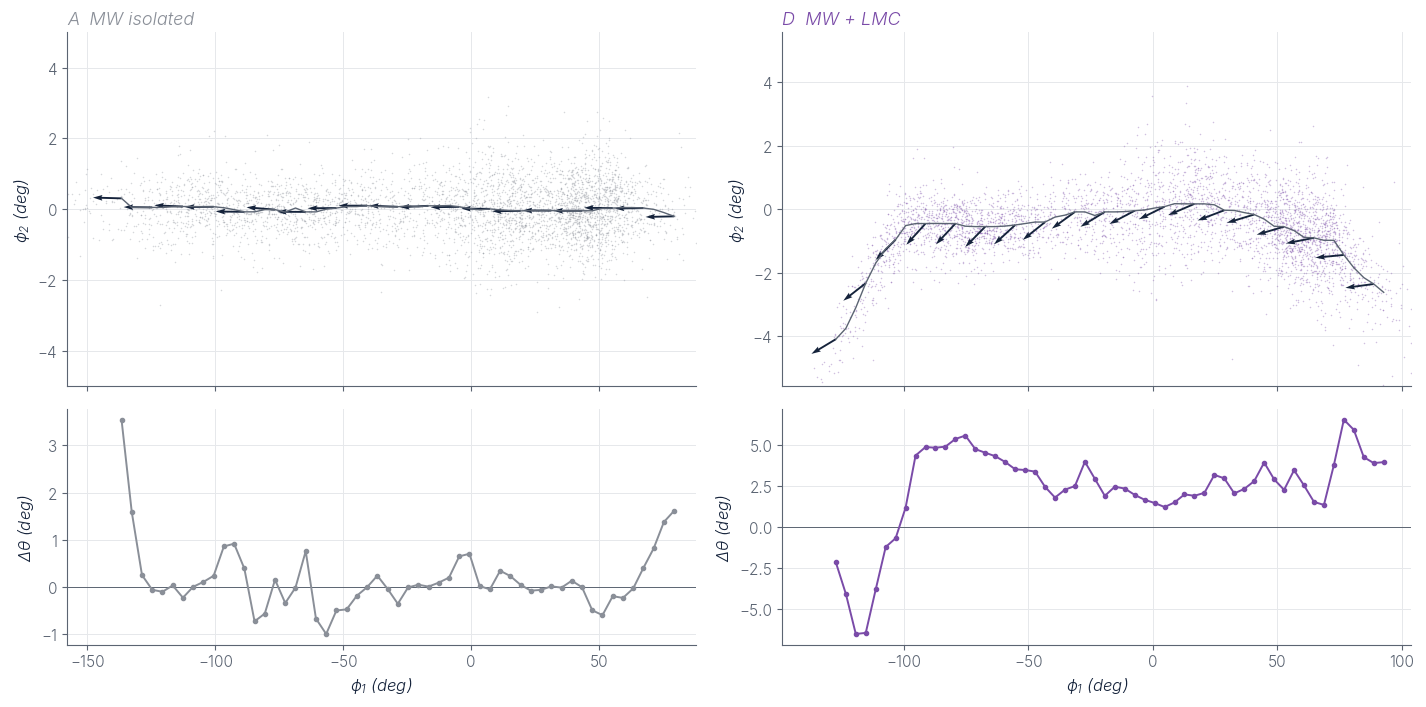

Figura: hito1_cielo_phi1_phi2.png 
Milestone 1, sky view. The same streams as seen from the Sun in great-circle coordinates (phi1, phi2) fitted to each stream. Arrows: direction of the median solar-reflex-corrected proper motion in 4-degree bins; line: stream track (running median of 5 bins). phi1 = 0 at the circular mean of the stream. Bottom: misalignment Delta theta = arctan(mu_phi2/mu_phi1) - arctan(dphi2/dphi1) per bin.


In [18]:
fig = F.cielo_gran_circulo(CORR, ("A", "D"))
PIE = 'Milestone 1, sky view. The same streams as seen from the Sun in great-circle coordinates (phi1, phi2) fitted to each stream. Arrows: direction of the median solar-reflex-corrected proper motion in 4-degree bins; line: stream track (running median of 5 bins). phi1 = 0 at the circular mean of the stream. Bottom: misalignment Delta theta = arctan(mu_phi2/mu_phi1) - arctan(dphi2/dphi1) per bin.'
E.guardar(fig, os.path.join(SAL, 'hito1_cielo_phi1_phi2.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito1_cielo_phi1_phi2.png', "\n" + PIE)

In [19]:
for m in "AD":
    d = RES[m]["todo"]
    print("%s: tilt del polo %.1f deg, tilt del plano %.1f deg, desalineamiento %.1f deg, longitud %.2f vueltas"
          % (m, d["tilt_polo_deg"], d["tilt_plano_deg"], d["desalineamiento_deg"], RES[m]["longitud_vueltas"]))
U.escribir_texto("Hito 1 (%s): progenitor polo -y, r_apo 100, f 0.5, 4 Gyr, 1e7 Msun. Peri %.1f kpc, e %.2f. "
                 "Tilt del polo A %.2f, D %.2f deg. Figuras y tabla en esta carpeta."
                 % (U.ahora(), r["peri_kpc"], r["ecc"], RES["A"]["todo"]["tilt_polo_deg"], RES["D"]["todo"]["tilt_polo_deg"]),
                 os.path.join(SAL, "registro.txt"))

A: tilt del polo 0.0 deg, tilt del plano 0.0 deg, desalineamiento 0.8 deg, longitud 0.60 vueltas
D: tilt del polo 9.9 deg, tilt del plano 8.6 deg, desalineamiento 3.1 deg, longitud 0.62 vueltas
